In [21]:
import * as d3 from "npm:d3";
import { JSDOM } from "npm:jsdom";

// 1. Create a virtual DOM instance
const dom = new JSDOM("<!DOCTYPE html><html><body></body></html>");

// 2. Expose the document globally for D3
globalThis.document = dom.window.document;

const text = await Deno.readTextFile("./penglings.csv");
const unfiltered_data = d3.csvParse(text, d3.autoType);

Document { location: [Getter/Setter] }

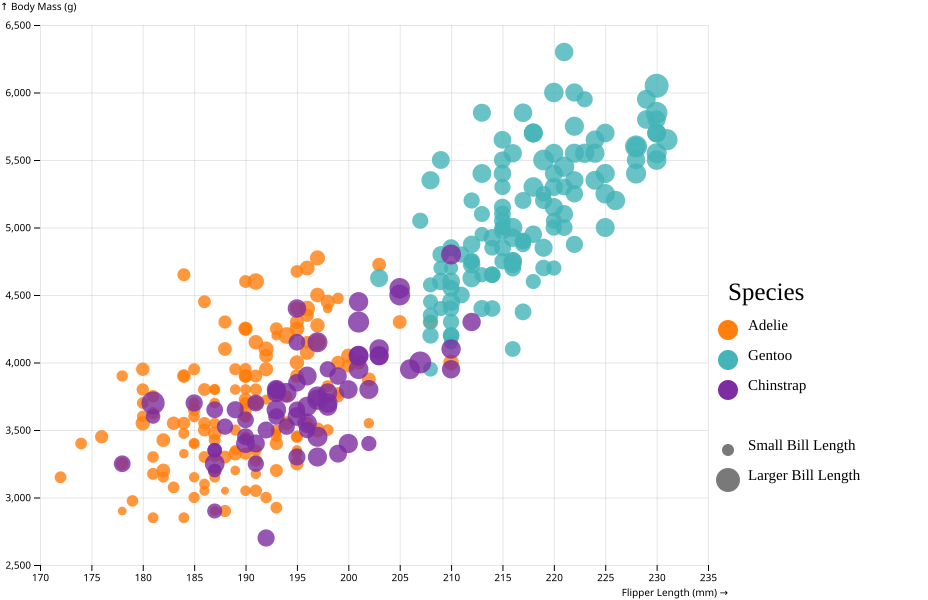

Promise { undefined }

In [33]:
const data = unfiltered_data.filter(d => d.flipper_length_mm != null && d.body_mass_g != null && d.bill_length_mm != null);

function chart() {
  const width = 928;
  const legendWidth = 200;
  const height = 600;
  const marginTop = 25;
  const marginRight = 20;
  const marginBottom = 35;
  const marginLeft = 40;

  // Create the positional scales.
  const x = d3.scaleLinear()
    .domain(d3.extent(data, d => d.flipper_length_mm)).nice()
    .range([marginLeft, width - marginRight - legendWidth]);
  const y = d3.scaleLinear()
    .domain(d3.extent(data, d => d.body_mass_g)).nice()
    .range([height - marginBottom, marginTop]);

  // Create the categorical scales.
  const color = d3.scaleOrdinal(data.map(d => d.species), ["#ff7f0e", "#44b4b8", "#7c2da1"]);
  const radiusScale = d3.scaleSqrt().domain(d3.extent(data, d => d.bill_length_mm)).range([4, 12]);

  // Create the SVG container.
  const svg = d3.create("svg")
      .attr("viewBox", [0, 0, width, height])
      .attr("width", width)
      .attr("height", height)
      .attr("style", "max-width: 100%; height: auto;");

  // Append the axes.
  svg.append("g")
      .attr("transform", `translate(0,${height - marginBottom})`)
      .call(d3.axisBottom(x).ticks(width / 80))
      .call(g => g.select(".domain").remove())
      .call(g => g.append("text")
          .attr("x", width-legendWidth)
          .attr("y", marginBottom - 4)
          .attr("fill", "currentColor")
          .attr("text-anchor", "end")
          .text("Flipper Length (mm) →"));

  svg.append("g")
      .attr("transform", `translate(${marginLeft},0)`)
      .call(d3.axisLeft(y))
      .call(g => g.select(".domain").remove())
      .call(g => g.append("text")
          .attr("x", -marginLeft)
          .attr("y", 10)
          .attr("fill", "currentColor")
          .attr("text-anchor", "start")
          .text("↑ Body Mass (g)"));

  // Add a grid.
  svg.append("g")
      .attr("stroke", "currentColor")
      .attr("stroke-opacity", 0.1)
      .call(g => g.append("g")
        .selectAll("line")
        .data(x.ticks())
        .join("line")
          .attr("x1", d => 0.5 + x(d))
          .attr("x2", d => 0.5 + x(d))
          .attr("y1", marginTop)
          .attr("y2", height - marginBottom))
      .call(g => g.append("g")
        .selectAll("line")
        .data(y.ticks())
        .join("line")
          .attr("y1", d => 0.5 + y(d))
          .attr("y2", d => 0.5 + y(d))
          .attr("x1", marginLeft)
          .attr("x2", width - marginRight - legendWidth));

  // Add the scatterplot symbols.
  svg.append("g")
      .attr("stroke-width", 1.5)
      .attr("font-family", "sans-serif")
      .attr("font-size", 10)
      .selectAll("circle")
        .data(data)
        .join("circle")
        .attr("cx", d => x(d.flipper_length_mm))
        .attr("cy", d => y(d.body_mass_g))
        .attr("fill", d => color(d.species))
        .attr("r", d => radiusScale(d.bill_length_mm))
        .attr("fill-opacity", 0.8)

    svg.append("text").attr("x", width - legendWidth).attr("y", 300).text("Species").style("font-size", "25px").attr("alignment-baseline","middle")
    svg.append("circle").attr("cx",width-legendWidth).attr("cy",330).attr("r", 10).style("fill", "#ff7f0e")
    svg.append("circle").attr("cx",width-legendWidth).attr("cy",360).attr("r", 10).style("fill", "#44b4b8")
    svg.append("circle").attr("cx",width-legendWidth).attr("cy",390).attr("r", 10).style("fill", "#7c2da1")
    svg.append("text").attr("x", width + 20 - legendWidth).attr("y", 330).text("Adelie").style("font-size", "15px").attr("alignment-baseline","middle")
    svg.append("text").attr("x", width + 20 - legendWidth).attr("y", 360).text("Gentoo").style("font-size", "15px").attr("alignment-baseline","middle")
    svg.append("text").attr("x", width + 20 - legendWidth).attr("y", 390).text("Chinstrap").style("font-size", "15px").attr("alignment-baseline","middle")

    svg.append("circle").attr("cx",width-legendWidth).attr("cy",450).attr("r", 6).style("fill", "#797979")
    svg.append("circle").attr("cx",width-legendWidth).attr("cy",480).attr("r", 12).style("fill", "#797979")
    svg.append("text").attr("x", width + 20 - legendWidth).attr("y", 450).text("Small Bill Length").style("font-size", "15px").attr("alignment-baseline","middle")
    svg.append("text").attr("x", width + 20 - legendWidth).attr("y", 480).text("Larger Bill Length").style("font-size", "15px").attr("alignment-baseline","middle")


  return Object.assign(svg.node(), {scales: {color, radiusScale}});
}

const node = chart();
Deno.jupyter.display({ "image/svg+xml": node.outerHTML }, { raw: true });